# 01 Build the dataset
CPU runtime. List the GenImage zips in place on Drive, sample a subset, extract only that and check it.

Refs: GenImage, Zhu et al. 2023 (arXiv 2306.08571)

In [1]:
# setup (same in every notebook)
import os, sys, subprocess

try:  # autoreload breaks on some Colab Python versions
    get_ipython().run_line_magic("load_ext", "autoreload")
    get_ipython().run_line_magic("autoreload", "2")
except Exception:
    print("autoreload unavailable, restart runtime after pulling changes")

REPO_URL = "https://github.com/Devanshu1503/CV_project_genimage-detection.git"
REPO_DIR = "/content/CV_project_genimage-detection"

if "google.colab" in sys.modules:
    if not os.path.isdir(REPO_DIR):
        subprocess.run(["git", "clone", REPO_URL, REPO_DIR], check=True)
    else:
        r = subprocess.run(["git", "-C", REPO_DIR, "pull", "--ff-only"], capture_output=True, text=True)
        print("[setup] git pull:", (r.stdout or r.stderr).strip())
else:  # local run from notebooks/
    REPO_DIR = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
os.chdir(REPO_DIR)
if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)

from src.colab_setup import setup
cfg, P = setup()  # config dict + paths

autoreload unavailable, restart runtime after pulling changes
[setup] Python 3.13.18 | Colab: True | repo: /content/CV_project_genimage-detection
Mounted at /content/drive
[setup] all packages in requirements-colab.txt already installed (nothing reinstalled).
[setup] apt packages already installed: ['p7zip-full']
[setup] No GPU (CPU only) | torch 2.11.0+cpu
[setup] seed = 42
[setup] Paths (colab):
  env            colab
  repo_root      /content/CV_project_genimage-detection
  genimage_root  /content/drive/MyDrive/genimage
  project_root   /content/drive/MyDrive/genimage_project
  work_dir       /content/work
  manifests      /content/drive/MyDrive/genimage_project/manifests
  raw_subset     /content/drive/MyDrive/genimage_project/raw_subset
  processed      /content/drive/MyDrive/genimage_project/processed
  features       /content/drive/MyDrive/genimage_project/features
  checkpoints    /content/drive/MyDrive/genimage_project/checkpoints
  results        /content/drive/MyDrive/genima

## Run flags
Slow steps only run when their flag is on.

In [2]:
RUN_SPEED_TEST = False    # step 4, local disk only
RUN_BENCHMARK = False    # step 4b, ~10-20 min, run once to pick the extraction settings
RUN_EXTRACTION = True   # step 11, turn on after checking step 10
RELIST = False           # redo the 7z listing even if manifests exist

In [3]:
import json
import shutil
import time
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

from src import archive_utils as au
from src import image_utils as iu
from src import manifest as mf
from src.config import generator_names, get_logger

pd.set_option("display.width", 200, "display.max_columns", 30)
log = get_logger("01_build_dataset", P.logs)  # also saved to logs/
GEN_FOLDERS = [g["folder"] for g in cfg["generators"]]
NAMES = generator_names(cfg)
SZ = cfg["seven_zip"]
SEED = cfg["project"]["seed"]
TRAIN_GEN = cfg["train_generator"]

# Part A: access and manifest
## Step 1: archive files on Drive

In [4]:
print(au.seven_zip_version(SZ["binary"]))

for gen in GEN_FOLDERS:
    gdir = P.genimage_root / gen
    if not gdir.exists():
        print(f"\n{gen}: FOLDER NOT FOUND at {gdir}")
        continue
    files = au.list_folder_files(gdir)
    print(f"\n{gen}: {len(files)} files, {files['gb'].sum():.1f} GB "
          f"(showing the first 3 and the last 2)")
    display(pd.concat([files.head(3), files.tail(2)]).drop_duplicates())

7z: 7-Zip 23.01 (x64) : Copyright (c) 1999-2023 Igor Pavlov : 2023-06-20

stable_diffusion_v_1_4: 30 files, 96.4 GB (showing the first 3 and the last 2)


,file,gb
0,imagenet_ai_0419_sdv4.z01,3.221
1,imagenet_ai_0419_sdv4.z02,3.221
2,imagenet_ai_0419_sdv4.z03,3.221
28,imagenet_ai_0419_sdv4.z29,3.221
29,imagenet_ai_0419_sdv4.zip,2.998



stable_diffusion_v_1_5: 32 files, 101.7 GB (showing the first 3 and the last 2)


,file,gb
0,imagenet_ai_0424_sdv5 (1).z26,3.221
1,imagenet_ai_0424_sdv5.z01,3.221
2,imagenet_ai_0424_sdv5.z02,3.221
30,imagenet_ai_0424_sdv5.z30,3.221
31,imagenet_ai_0424_sdv5.zip,1.887



Midjourney: 71 files, 227.5 GB (showing the first 3 and the last 2)


,file,gb
0,imagenet_midjourney.z01,3.221
1,imagenet_midjourney.z02,3.221
2,imagenet_midjourney.z03,3.221
69,imagenet_midjourney.z70,3.221
70,imagenet_midjourney.zip,1.983


... (6 outputs left out)


VQDM: 12 files, 38.2 GB (showing the first 3 and the last 2)


,file,gb
0,imagenet_ai_0419_vqdm.z01,3.221
1,imagenet_ai_0419_vqdm.z02,3.221
2,imagenet_ai_0419_vqdm.z03,3.221
10,imagenet_ai_0419_vqdm.z11,3.221
11,imagenet_ai_0419_vqdm.zip,2.771



BigGAN: 8 files, 24.2 GB (showing the first 3 and the last 2)


,file,gb
0,imagenet_ai_0419_biggan.z01,3.221
1,imagenet_ai_0419_biggan.z02,3.221
2,imagenet_ai_0419_biggan.z03,3.221
6,imagenet_ai_0419_biggan.z07,3.221
7,imagenet_ai_0419_biggan.zip,1.687


In [5]:
inv = au.archive_inventory(P.genimage_root, GEN_FOLDERS)
inv.to_csv(P.manifests / "archive_inventory.csv", index=False)
display(inv)
bad = inv.loc[inv["status"] != "ok"]
if len(bad):
    log.warning(f"{len(bad)} generator(s) have a problem (see 'status'); they will be skipped later:\n{bad}")
print(f"Total archive size on Drive: {inv['total_gb'].sum():.0f} GB")

,generator,base,zip_path,n_parts,has_zip,total_gb,status
0,stable_diffusion_v_1_4,imagenet_ai_0419_sdv4,/content/drive/MyDrive/genimage/stable_diffusi...,29,True,96.41,ok
1,stable_diffusion_v_1_5,imagenet_ai_0424_sdv5,/content/drive/MyDrive/genimage/stable_diffusi...,30,True,98.52,ok
2,stable_diffusion_v_1_5,imagenet_ai_0424_sdv5 (1),None,1,False,3.22,MISSING final .zip
3,Midjourney,imagenet_midjourney,/content/drive/MyDrive/genimage/Midjourney/ima...,70,True,227.47,ok
4,wukong,imagenet_ai_0424_wukong,/content/drive/MyDrive/genimage/wukong/imagene...,30,True,97.24,ok
5,ADM,imagenet_ai_0508_adm,/content/drive/MyDrive/genimage/ADM/imagenet_a...,12,True,38.84,ok
6,glide,imagenet_glide,/content/drive/MyDrive/genimage/glide/imagenet...,10,True,32.26,ok
7,VQDM,imagenet_ai_0419_vqdm,/content/drive/MyDrive/genimage/VQDM/imagenet_...,11,True,38.20,ok
8,BigGAN,imagenet_ai_0419_biggan,/content/drive/MyDrive/genimage/BigGAN/imagene...,7,True,24.24,ok


2026-11-04 00:18:54 | WARNING | 1 generator(s) have a problem (see 'status'); they will be skipped later:
                generator                       base zip_path  n_parts  has_zip  total_gb              status
2  stable_diffusion_v_1_5  imagenet_ai_0424_sdv5 (1)     None        1    False      3.22  MISSING final .zip
Total archive size on Drive: 656 GB


## Steps 2-3: list SD1.4 in place
Stops with the exact 7z error if the split zip can't be opened.

In [6]:
try:
    t0 = time.time()
    m_sd, secs = mf.list_generator_to_manifest(TRAIN_GEN, inv, P.manifests, P.work_dir, cfg,
                                               relist=RELIST, logger=log)
    print(f"Listing took {time.time() - t0:.1f}s total" + (f" (7z: {secs:.1f}s)" if secs else " (loaded from disk)"))
except au.SevenZipError as e:
    raise RuntimeError(
        "STOP: 7-Zip could not open the split archive directly from Drive.\n"
        f"Exact error:\n{e}\n\n"
        "Do NOT copy the whole archive to work around this. Check that every .zNN part and the .zip "
        "are present (inventory table above) and that the Drive shortcut points at the right folder. "
        "If p7zip 16.02 cannot read this split-zip format, a newer official 7-Zip build (7zz) may: "
        "install it and set seven_zip.binary in configs/config.yaml.") from e

print(f"{len(m_sd):,} files in {TRAIN_GEN}")
display(m_sd.head())

2026-11-04 00:18:54 | INFO | stable_diffusion_v_1_4: manifest already exists -> loading manifest_stable_diffusion_v_1_4.csv.gz
Listing took 1.8s total (loaded from disk)
336,000 files in stable_diffusion_v_1_4


,generator,archive_path,inner_path,top_folder,split,label,filename,ext,is_image,uncompressed_bytes,imagenet_class,class_source
0,stable_diffusion_v_1_4,/content/drive/MyDrive/genimage/stable_diffusi...,imagenet_ai_0419_sdv4/train/ai/000_sdv4_00000.png,imagenet_ai_0419_sdv4,train,ai,000_sdv4_00000.png,.png,True,442023,0,leading_int
1,stable_diffusion_v_1_4,/content/drive/MyDrive/genimage/stable_diffusi...,imagenet_ai_0419_sdv4/train/ai/000_sdv4_00001.png,imagenet_ai_0419_sdv4,train,ai,000_sdv4_00001.png,.png,True,535041,0,leading_int
2,stable_diffusion_v_1_4,/content/drive/MyDrive/genimage/stable_diffusi...,imagenet_ai_0419_sdv4/train/ai/000_sdv4_00002.png,imagenet_ai_0419_sdv4,train,ai,000_sdv4_00002.png,.png,True,496627,0,leading_int
3,stable_diffusion_v_1_4,/content/drive/MyDrive/genimage/stable_diffusi...,imagenet_ai_0419_sdv4/train/ai/000_sdv4_00004.png,imagenet_ai_0419_sdv4,train,ai,000_sdv4_00004.png,.png,True,511449,0,leading_int
4,stable_diffusion_v_1_4,/content/drive/MyDrive/genimage/stable_diffusi...,imagenet_ai_0419_sdv4/train/ai/000_sdv4_00005.png,imagenet_ai_0419_sdv4,train,ai,000_sdv4_00005.png,.png,True,481647,0,leading_int


Check the folder layout and how often a class id can be parsed from the filename.

In [7]:
print("Top-level folders:", m_sd["top_folder"].value_counts().to_dict())
display(pd.crosstab([m_sd["split"], m_sd["label"]], m_sd["class_source"].fillna("none"), margins=True))
for (lab, src), g in m_sd.groupby(["label", m_sd["class_source"].fillna("none")]):
    print(f"{lab:<7} {src:<12} examples: {g['filename'].head(3).tolist()}")

Top-level folders: {'imagenet_ai_0419_sdv4': 336000}


class_source  leading_int  none  synset     All
split label                                    
train ai           162000     0       0  162000
      nature            0     0  162000  162000
val   ai             6000     0       0    6000
      nature            0  6000       0    6000
All                168000  6000  162000  336000

ai      leading_int  examples: ['000_sdv4_00000.png', '000_sdv4_00001.png', '000_sdv4_00002.png']
nature  none         examples: ['ILSVRC2012_val_00000037.JPEG', 'ILSVRC2012_val_00000056.JPEG', 'ILSVRC2012_val_00000060.JPEG']
nature  synset       examples: ['n01440764_10043.JPEG', 'n01440764_10048.JPEG', 'n01440764_10211.JPEG']


## Step 4: extraction speed test
100 files to local disk, then real format vs extension.

In [8]:
if RUN_SPEED_TEST:
    n = SZ["speed_test_n_per_label"]
    imgs = m_sd.loc[m_sd["is_image"] & m_sd["label"].isin(["ai", "nature"])]
    test = pd.concat([imgs.loc[imgs["label"] == lab].sample(n, random_state=SEED) for lab in ["ai", "nature"]])
    test_dir = P.work_dir / "test"
    shutil.rmtree(test_dir, ignore_errors=True)
    found, secs = [], 0.0
    for zp, g in test.groupby("archive_path"):
        res = au.extract_files(zp, g["inner_path"].tolist(), test_dir, SZ["binary"], SZ["extract_timeout_sec"])
        found += res["found"]
        secs += res["seconds"]
        if res["missing"]:
            log.warning(f"{len(res['missing'])} files missing after extraction, e.g. {res['missing'][:3]}")
    mb = test.loc[test["inner_path"].isin(found), "uncompressed_bytes"].sum() / 1e6
    print(f"Extracted {len(found)}/{len(test)} files, {mb:.1f} MB in {secs:.1f}s "
          f"-> {secs / max(len(found), 1):.2f} s/image, {mb / max(secs, 1e-9):.2f} MB/s")
    meta = pd.DataFrame([iu.image_metadata(test_dir / p, with_hashes=False) for p in found])
    meta["ext"] = [Path(p).suffix.lower() for p in found]
    meta["label"] = test.set_index("inner_path").loc[found, "label"].values
    print("\nReal format (from file content) vs extension:")
    display(pd.crosstab([meta["label"], meta["ext"]], meta["real_format"].fillna("UNREADABLE")))
    display(meta.groupby("label")[["width", "height", "file_bytes", "jpeg_quality"]].describe().T)
    est_h = secs / max(len(found), 1) * (2 * cfg["sampling"]["train_per_label"]
                                          + 2 * len(GEN_FOLDERS) * cfg["sampling"]["test_per_label"]) / 3600
    print(f"\nRough extrapolation for the full sample at this speed: ~{est_h:.1f} h "
          "(batches are larger than this test, so it is likely faster).")

## Step 4b: speed benchmark
Parallel 7z from Drive with 1/4/8 workers vs copying an archive part to local disk.

In [9]:
if not RUN_BENCHMARK:
    print("RUN_BENCHMARK = False -> skipping the benchmark.")
else:
    bench_dir = P.work_dir / "bench"
    shutil.rmtree(bench_dir, ignore_errors=True)
    imgs = m_sd.loc[m_sd["is_image"] & m_sd["label"].isin(["ai", "nature"])]
    sd_zip = imgs["archive_path"].iloc[0]
    # different files per run so Drive caching doesn't help the later runs
    tr = imgs.loc[imgs["split"] == "train"]
    tr = tr.sample(min(600, len(tr)), random_state=SEED)
    va = imgs.loc[imgs["split"] == "val"]
    va = va.sample(min(200, len(va)), random_state=SEED)
    k = len(tr) // 3
    runs = [("train", 1, tr.iloc[:k]), ("train", 4, tr.iloc[k:2 * k]), ("train", 8, tr.iloc[2 * k:3 * k]),
            ("val", 4, va)]
    rows = []
    for split, w, files in runs:
        out = bench_dir / f"{split}_{w}"
        res = au.parallel_extract(sd_zip, files["inner_path"].tolist(), out, w, SZ["binary"], SZ["extract_timeout_sec"])
        n = len(res["found"])
        mb = files.loc[files["inner_path"].isin(res["found"]), "uncompressed_bytes"].sum() / 1e6
        rows.append({"split": split, "workers": w, "files": n, "seconds": round(res["seconds"], 1),
                     "s_per_image": res["seconds"] / max(n, 1), "MB_per_s": mb / max(res["seconds"], 1e-9)})
        if res["missing"]:
            log.warning(f"benchmark {split}/{w}: {len(res['missing'])} files missing")
        shutil.rmtree(out, ignore_errors=True)
    bench = pd.DataFrame(rows)
    display(bench.round(3))

    # copy one part to local disk
    parts = au.archive_part_files(sd_zip)[:-1]
    part = parts[len(parts) // 2] if parts else Path(sd_zip)
    copy_mbps = max(au.copy_file_timed(part, bench_dir / part.name), 1e-6)
    (bench_dir / part.name).unlink()
    print(f"Copy {part.name} ({part.stat().st_size / 1e9:.2f} GB) Drive -> local: {copy_mbps:.0f} MB/s")

    # rough estimate for the full sample
    plan_file = P.manifests / "sampling_plan.csv"
    if plan_file.exists():
        pl = mf.read_csv(plan_file)
        n_total, n_sd = len(pl), int((pl["generator"] == TRAIN_GEN).sum())
    else:
        sp = cfg["sampling"]
        n_total = 2 * sp["train_per_label"] + 2 * len(GEN_FOLDERS) * sp["test_per_label"]
        n_sd = 2 * sp["train_per_label"] + 2 * sp["test_per_label"]
    best = bench.loc[bench["split"] == "train"].sort_values("s_per_image").iloc[0]
    s_img, w_best = best["s_per_image"], int(best["workers"])
    LOCAL_SPEEDUP = 10  # guess (not measured): extracting from local disk vs Drive
    sd_gb = inv.loc[inv["generator"] == TRAIN_GEN, "total_gb"].sum()
    h_drive = n_total * s_img / 3600
    h_copy = sd_gb * 1e3 / copy_mbps / 3600
    h_local = h_copy + n_sd * s_img / LOCAL_SPEEDUP / 3600 + (n_total - n_sd) * s_img / 3600
    free_gb = shutil.disk_usage(P.work_dir).free / 1e9
    fits = sd_gb < free_gb - SZ["local_copy_margin_gb"]
    print(f"\nBest from Drive: {w_best} workers, {s_img:.3f} s/image")
    print(f"A) parallel from Drive, all {n_total:,} files: ~{h_drive:.1f} h")
    print(f"B) copy SD1.4 ({sd_gb:.0f} GB, ~{h_copy:.1f} h) + local extract of {n_sd:,} "
          f"(assumes {LOCAL_SPEEDUP}x faster) + Drive for the rest: ~{h_local:.1f} h"
          + ("" if fits else f"  [does NOT fit: {free_gb:.0f} GB free]"))
    if fits and h_local < h_drive:
        print(f"\nRecommendation: B. In configs/config.yaml set\n  extract_workers: {w_best}\n"
              f"  copy_local_generators: [{TRAIN_GEN}]")
    else:
        print(f"\nRecommendation: A. In configs/config.yaml set\n  extract_workers: {w_best}\n"
              "  copy_local_generators: []")

RUN_BENCHMARK = False -> skipping the benchmark.


## Step 5: list all 8 generators
Resumable, failed generators are logged and skipped.

In [10]:
manifests, status = {}, []
for gen in GEN_FOLDERS:
    try:
        t0 = time.time()
        m, secs = mf.list_generator_to_manifest(gen, inv, P.manifests, P.work_dir, cfg, relist=RELIST, logger=log)
        manifests[gen] = m
        status.append({"generator": gen, "files": len(m), "seconds": round(time.time() - t0, 1),
                       "status": "listed" if secs is not None else "loaded"})
    except Exception as e:
        log.error(f"{gen}: FAILED -> {e}")
        status.append({"generator": gen, "files": 0, "seconds": round(time.time() - t0, 1),
                       "status": f"ERROR: {str(e).splitlines()[0][:120]}"})
display(pd.DataFrame(status))

m_all = pd.concat(manifests.values(), ignore_index=True)
m_all.to_csv(P.manifests / "manifest_all.csv.gz", index=False)
print(f"manifest_all: {len(m_all):,} files from {m_all['generator'].nunique()} generators "
      f"-> {P.manifests / 'manifest_all.csv.gz'}")

2026-11-04 00:18:56 | INFO | stable_diffusion_v_1_4: manifest already exists -> loading manifest_stable_diffusion_v_1_4.csv.gz
2026-11-04 00:18:57 | INFO | stable_diffusion_v_1_5: manifest already exists -> loading manifest_stable_diffusion_v_1_5.csv.gz
2026-11-04 00:18:59 | INFO | Midjourney: manifest already exists -> loading manifest_Midjourney.csv.gz
2026-11-04 00:19:01 | INFO | wukong: manifest already exists -> loading manifest_wukong.csv.gz
2026-11-04 00:19:03 | INFO | ADM: manifest already exists -> loading manifest_ADM.csv.gz
2026-11-04 00:19:04 | INFO | glide: manifest already exists -> loading manifest_glide.csv.gz
2026-11-04 00:19:06 | INFO | VQDM: manifest already exists -> loading manifest_VQDM.csv.gz
2026-11-04 00:19:08 | INFO | BigGAN: manifest already exists -> loading manifest_BigGAN.csv.gz


,generator,files,seconds,status
0,stable_diffusion_v_1_4,336000,1.0,loaded
1,stable_diffusion_v_1_5,335274,1.8,loaded
2,Midjourney,335701,1.7,loaded
3,wukong,334739,2.0,loaded
4,ADM,331453,1.6,loaded
5,glide,336000,1.8,loaded
6,VQDM,336000,1.6,loaded
7,BigGAN,336000,1.7,loaded


manifest_all: 2,681,167 files from 8 generators -> /content/drive/MyDrive/genimage_project/manifests/manifest_all.csv.gz


## Step 6: manifest summary

In [11]:
print("Files per generator x split x label:")
display(mf.manifest_summary(m_all))

print("File extension x label (all generators):")
display(pd.crosstab(m_all["ext"], m_all["label"], margins=True))

print("Top-level folder(s) per generator:")
display(m_all.groupby("generator")["top_folder"].unique().to_frame())

unknown = m_all.loc[(m_all["split"] == "unknown") | (m_all["label"] == "unknown")]
non_img = m_all.loc[~m_all["is_image"]]
print(f"Files with unknown split/label: {len(unknown):,}")
if len(unknown):
    display(unknown.groupby(["generator", "top_folder"]).size().rename("n").reset_index().head(20))
print(f"Non-image files: {len(non_img):,}")
if len(non_img):
    display(non_img[["generator", "inner_path", "uncompressed_bytes"]].head(20))

print("ImageNet class parsing per generator x label:")
display(pd.crosstab([m_all["generator"], m_all["label"]], m_all["class_source"].fillna("none")))

Files per generator x split x label:


split                    train           val       
label                       ai  nature    ai nature
generator                                          
ADM                     162000  157453  6000   6000
BigGAN                  162000  162000  6000   6000
Midjourney              162000  161701  6000   6000
VQDM                    162000  162000  6000   6000
glide                   162000  162000  6000   6000
stable_diffusion_v_1_4  162000  162000  6000   6000
stable_diffusion_v_1_5  166000  153274  8000   8000
wukong                  162000  160739  6000   6000

File extension x label (all generators):


label,ai,nature,All
ext,,,
.jpeg,0,1331167,1331167
.png,1350000,0,1350000
All,1350000,1331167,2681167


Top-level folder(s) per generator:


,top_folder
generator,
ADM,[imagenet_ai_0508_adm]
BigGAN,[imagenet_ai_0419_biggan]
Midjourney,[imagenet_midjourney]
VQDM,[imagenet_ai_0419_vqdm]
glide,[imagenet_glide]
stable_diffusion_v_1_4,[imagenet_ai_0419_sdv4]
stable_diffusion_v_1_5,[imagenet_ai_0424_sdv5]
wukong,[imagenet_ai_0424_wukong]


Files with unknown split/label: 0
Non-image files: 0
ImageNet class parsing per generator x label:


class_source                   leading_int    none  synset
generator              label                              
ADM                    ai           168000       0       0
                       nature            0    6000  157453
BigGAN                 ai           168000       0       0
                       nature            0    6000  162000
Midjourney             ai           168000       0       0
                       nature            0    6000  161701
VQDM                   ai                0  168000       0
                       nature            0    6000  162000
glide                  ai                0  168000       0
                       nature            0    6000  162000
stable_diffusion_v_1_4 ai           168000       0       0
                       nature            0    6000  162000
stable_diffusion_v_1_5 ai           174000       0       0
                       nature            0    8000  153274
wukong                 ai           168000       0       0
                       nature            0    6000  160739

## Step 7: leakage check by filename
Do real filenames repeat across generators or train/val?

In [12]:
leak = mf.filename_leakage_report(m_all)
print(json.dumps(leak["summary"], indent=2))
print("\nNumber of shared 'nature' filenames between generators (diagonal = total per generator):")
display(leak["overlap_matrix"])
with open(P.results / "filename_leakage_summary.json", "w") as f:
    json.dump(leak["summary"], f, indent=2)

{
  "n_unique_nature_filenames": 1331167,
  "in_more_than_one_generator": 0,
  "in_both_train_and_val": 0,
  "repeated_within_a_generator": 0
}

Number of shared 'nature' filenames between generators (diagonal = total per generator):


,ADM,BigGAN,Midjourney,VQDM,glide,stable_diffusion_v_1_4,stable_diffusion_v_1_5,wukong
ADM,163453,0,0,0,0,0,0,0
BigGAN,0,168000,0,0,0,0,0,0
Midjourney,0,0,167701,0,0,0,0,0
VQDM,0,0,0,168000,0,0,0,0
glide,0,0,0,0,168000,0,0,0
stable_diffusion_v_1_4,0,0,0,0,0,168000,0,0
stable_diffusion_v_1_5,0,0,0,0,0,0,161274,0
wukong,0,0,0,0,0,0,0,166739


# Part B: sampling and extraction
## Steps 8-9: draw the sample
Test reals whose filename is in the training sample are removed before sampling.

In [13]:
plan = mf.build_sampling_plan(m_all, cfg, logger=log)
plan.to_csv(P.manifests / "sampling_plan.csv", index=False)
display(plan.groupby(["generator", "role", "label"]).size().unstack("label"))

overlap = set(plan.loc[plan.role == "train", "filename"]) & set(plan.loc[plan.role == "test", "filename"])
print(f"Filenames shared by train and test samples: {len(overlap)} (must be 0)")
assert not overlap

print("ImageNet class coverage of the sample:")
display(mf.class_coverage(plan))

label                           ai  nature
generator              role               
ADM                    test    500     500
BigGAN                 test    500     500
Midjourney             test    500     500
VQDM                   test    500     500
glide                  test    500     500
stable_diffusion_v_1_4 test    500     500
                       train  5000    5000
stable_diffusion_v_1_5 test    500     500
wukong                 test    500     500

Filenames shared by train and test samples: 0 (must be 0)
ImageNet class coverage of the sample:


,generator,role,label,n_images,n_with_class,n_classes
0,ADM,test,ai,500,500,500
1,ADM,test,nature,500,0,0
2,BigGAN,test,ai,500,500,500
3,BigGAN,test,nature,500,0,0
4,Midjourney,test,ai,500,500,500
5,Midjourney,test,nature,500,0,0
6,VQDM,test,ai,500,0,0
7,VQDM,test,nature,500,0,0
8,glide,test,ai,500,0,0
9,glide,test,nature,500,0,0


## Step 10: size estimate
Stops if the sample is over the Drive budget.

In [14]:
size = plan.groupby(["generator", "role", "label"])["uncompressed_bytes"].sum().div(1e9).round(3)
display(size.unstack("label"))
total_gb = mf.estimate_size_gb(plan)
budget = cfg["sampling"]["drive_budget_gb"]
print(f"Estimated raw subset size: {total_gb:.2f} GB (budget {budget} GB)")
if total_gb > budget:
    sug = mf.suggest_sample_sizes(plan, budget, cfg["sampling"]["train_per_label"], cfg["sampling"]["test_per_label"])
    raise RuntimeError(f"STOP: sample is over the Drive budget. Suggestion: {sug}. "
                       "Edit sampling.* in configs/config.yaml, push, and re-run.")
print("OK: within budget.")

label                            ai  nature
generator              role                
ADM                    test   0.059   0.071
BigGAN                 test   0.015   0.065
Midjourney             test   0.624   0.067
VQDM                   test   0.057   0.070
glide                  test   0.038   0.070
stable_diffusion_v_1_4 test   0.230   0.070
                       train  2.298   0.575
stable_diffusion_v_1_5 test   0.227   0.071
wukong                 test   0.233   0.067

Estimated raw subset size: 4.91 GB (budget 6.0 GB)
OK: within budget.


## Step 11: extract and copy to Drive
Original bytes, resumable, parallel 7z (`extract_workers`), optional local archive copy (`copy_local_generators`).

In [15]:
def on_file(local_path, row):
    """Metadata from the local copy."""
    return iu.image_metadata(local_path, with_hashes=True, hash_size=cfg["dedup"]["phash_size"])


if not RUN_EXTRACTION:
    print("RUN_EXTRACTION = False -> skipping extraction. Set it to True at the top to run this step.")
else:
    summary = []
    for gen in GEN_FOLDERS:
        sub = plan.loc[plan["generator"] == gen]
        if sub.empty:
            log.warning(f"{gen}: nothing sampled (listing failed?) -> skipped")
            continue
        t0 = time.time()
        log.info(f"=== {gen}: {len(sub)} files, {sub['uncompressed_bytes'].sum() / 1e9:.2f} GB ===")
        try:
            for zp, s in sub.groupby("archive_path"):
                src_zip = zp
                todo = ~s["raw_relpath"].map(lambda r: (P.project_root / r).exists())
                if gen in SZ["copy_local_generators"] and todo.any():
                    local_zip = au.copy_archive_local(zp, P.work_dir / "archives" / gen,
                                                      SZ["local_copy_margin_gb"], logger=log)
                    src_zip = local_zip if local_zip is not None else zp
                st, extra = au.extract_sample_to_drive(
                    s, src_zip, P.work_dir / "extract" / gen, P.project_root, batch_size=SZ["extract_batch_size"],
                    binary=SZ["binary"], timeout=SZ["extract_timeout_sec"], on_file=on_file, logger=log,
                    workers=SZ["extract_workers"])
                if str(src_zip) != str(zp):  # done with the local copy
                    shutil.rmtree(P.work_dir / "archives" / gen, ignore_errors=True)
                    log.info(f"{gen}: deleted local archive copy")
                st.to_csv(P.logs / f"extraction_status_{gen}.csv", mode="a", index=False,
                          header=not (P.logs / f"extraction_status_{gen}.csv").exists())
                if extra:
                    mfile = P.manifests / f"raw_metadata_{gen}.csv"
                    pd.DataFrame(extra).to_csv(mfile, mode="a", index=False, header=not mfile.exists())
                counts = st["status"].value_counts().to_dict()
                summary.append({"generator": gen, **counts, "minutes": round((time.time() - t0) / 60, 1)})
                log.info(f"{gen}: {counts}")
        except Exception as e:
            log.error(f"{gen}: extraction FAILED -> {e}")
            summary.append({"generator": gen, "error": str(e).splitlines()[0][:150]})
    display(pd.DataFrame(summary))

2026-11-04 00:19:56 | INFO | === stable_diffusion_v_1_4: 11000 files, 3.17 GB ===
2026-11-04 00:20:22 | INFO |   11000 files sampled | 4418 already on Drive | 6582 to extract | 6 worker(s)


7z batches:   0%|          | 0/7 [00:00<?, ?it/s]

2026-11-04 00:24:01 | INFO |   batch 4/7: 1000/1000 files, 106 MB in 219s (0.5 MB/s)
2026-11-04 00:24:15 | INFO |   batch 5/7: 1000/1000 files, 116 MB in 234s (0.5 MB/s)
2026-11-04 00:24:34 | INFO |   batch 6/7: 1000/1000 files, 264 MB in 252s (1.0 MB/s)
2026-11-04 00:27:19 | INFO |   batch 7/7: 582/582 files, 107 MB in 45s (2.4 MB/s)
2026-11-04 00:27:34 | INFO |   batch 3/7: 1000/1000 files, 316 MB in 432s (0.7 MB/s)
2026-11-04 00:28:58 | INFO |   batch 1/7: 1000/1000 files, 467 MB in 516s (0.9 MB/s)
2026-11-04 00:29:00 | INFO |   batch 2/7: 1000/1000 files, 451 MB in 518s (0.9 MB/s)
2026-11-04 00:29:49 | INFO | stable_diffusion_v_1_4: {'extracted': 6582, 'already_done': 4418}
2026-11-04 00:29:49 | INFO | === stable_diffusion_v_1_5: 1000 files, 0.30 GB ===
2026-11-04 00:29:49 | INFO |   1000 files sampled | 0 already on Drive | 1000 to extract | 6 worker(s)


7z batches:   0%|          | 0/6 [00:00<?, ?it/s]

2026-11-04 00:30:14 | INFO |   batch 5/6: 167/167 files, 28 MB in 25s (1.1 MB/s)
2026-11-04 00:30:23 | INFO |   batch 4/6: 167/167 files, 22 MB in 34s (0.7 MB/s)
2026-11-04 00:30:23 | INFO |   batch 6/6: 165/165 files, 20 MB in 34s (0.6 MB/s)
2026-11-04 00:30:34 | INFO |   batch 3/6: 167/167 files, 75 MB in 45s (1.7 MB/s)
2026-11-04 00:30:39 | INFO |   batch 1/6: 167/167 files, 76 MB in 50s (1.5 MB/s)
2026-11-04 00:30:40 | INFO |   batch 2/6: 167/167 files, 75 MB in 51s (1.5 MB/s)
2026-11-04 00:30:58 | INFO | stable_diffusion_v_1_5: {'extracted': 1000}
2026-11-04 00:30:58 | INFO | === Midjourney: 1000 files, 0.69 GB ===
2026-11-04 00:30:59 | INFO |   1000 files sampled | 0 already on Drive | 1000 to extract | 6 worker(s)


7z batches:   0%|          | 0/6 [00:00<?, ?it/s]

... (8 outputs left out)

2026-11-04 00:35:43 | INFO |   batch 1/6: 167/167 files, 20 MB in 27s (0.7 MB/s)
2026-11-04 00:35:44 | INFO |   batch 6/6: 165/165 files, 24 MB in 29s (0.8 MB/s)
2026-11-04 00:35:53 | INFO |   batch 3/6: 167/167 files, 18 MB in 37s (0.5 MB/s)
2026-11-04 00:35:53 | INFO |   batch 2/6: 167/167 files, 19 MB in 37s (0.5 MB/s)
2026-11-04 00:35:54 | INFO |   batch 4/6: 167/167 files, 23 MB in 39s (0.6 MB/s)
2026-11-04 00:36:01 | INFO |   batch 5/6: 167/167 files, 22 MB in 45s (0.5 MB/s)
2026-11-04 00:36:08 | INFO | VQDM: {'extracted': 1000}
2026-11-04 00:36:08 | INFO | === BigGAN: 1000 files, 0.08 GB ===
2026-11-04 00:36:09 | INFO |   1000 files sampled | 0 already on Drive | 1000 to extract | 6 worker(s)


7z batches:   0%|          | 0/6 [00:00<?, ?it/s]

2026-11-04 00:36:34 | INFO |   batch 4/6: 167/167 files, 22 MB in 25s (0.9 MB/s)
2026-11-04 00:36:37 | INFO |   batch 1/6: 167/167 files, 5 MB in 29s (0.2 MB/s)
2026-11-04 00:36:38 | INFO |   batch 3/6: 167/167 files, 5 MB in 30s (0.2 MB/s)
2026-11-04 00:36:39 | INFO |   batch 2/6: 167/167 files, 5 MB in 30s (0.2 MB/s)
2026-11-04 00:36:42 | INFO |   batch 6/6: 165/165 files, 21 MB in 33s (0.6 MB/s)
2026-11-04 00:36:44 | INFO |   batch 5/6: 167/167 files, 22 MB in 36s (0.6 MB/s)
2026-11-04 00:36:55 | INFO | BigGAN: {'extracted': 1000}


,generator,extracted,already_done,minutes
0,stable_diffusion_v_1_4,6582,4418.0,9.9
1,stable_diffusion_v_1_5,1000,NaN,1.2
2,Midjourney,1000,NaN,1.8
3,wukong,1000,NaN,0.9
4,ADM,1000,NaN,0.8
5,glide,1000,NaN,0.7
6,VQDM,1000,NaN,0.9
7,BigGAN,1000,NaN,0.8


## Step 12: verify, hash, remove leakage
Test images that duplicate a training image (md5 or pHash) get dropped.

In [16]:
plan = mf.read_csv(P.manifests / "sampling_plan.csv")
plan["exists"] = [(P.project_root / r).exists() for r in plan["raw_relpath"]]
print(f"Sampled files present on Drive: {plan['exists'].sum():,}/{len(plan):,}")
if not plan["exists"].all():
    display(plan.loc[~plan["exists"]].groupby(["generator", "role", "label"]).size().rename("missing"))
EXTRACTED = bool(plan["exists"].any())
if not EXTRACTED:
    print("nothing extracted yet, run step 11 first (steps 12-13 skipped)")

if EXTRACTED:
    meta_files = sorted(P.manifests.glob("raw_metadata_*.csv"))
    meta = pd.concat([mf.read_csv(f) for f in meta_files], ignore_index=True) if meta_files else pd.DataFrame(columns=["sample_id"])
    if "on_file_error" in meta:
        meta = meta.loc[meta["on_file_error"].isna()].drop(columns="on_file_error")
    meta = meta.drop_duplicates("sample_id", keep="last")
    need = plan.loc[plan["exists"] & ~plan["sample_id"].isin(meta["sample_id"])]
    print(f"Metadata available for {len(meta):,} files; computing it for {len(need):,} more from Drive...")
    if len(need):
        extra = iu.metadata_many([P.project_root / r for r in need["raw_relpath"]], n_threads=cfg["dedup"]["n_threads"],
                                 hash_size=cfg["dedup"]["phash_size"])
        extra = pd.DataFrame(extra).assign(sample_id=need["sample_id"].values)
        meta = pd.concat([meta, extra], ignore_index=True)
    meta.to_csv(P.manifests / "raw_metadata.csv", index=False)

    sub = plan.loc[plan["exists"]].merge(meta, on="sample_id", how="left")
    unreadable = sub.loc[sub["readable"] != True]
    print(f"Unreadable / corrupt files: {len(unreadable)}")
    if len(unreadable):
        display(unreadable[["sample_id", "error"]].head(20))

Sampled files present on Drive: 18,000/18,000
Metadata available for 13,582 files; computing it for 4,418 more from Drive...


metadata:   0%|          | 0/4418 [00:00<?, ?it/s]

Unreadable / corrupt files: 0


In [17]:
if EXTRACTED:
    ok = sub.loc[sub["readable"] == True].reset_index(drop=True)
    pairs = mf.duplicate_pairs(ok, cfg["dedup"]["near_dup_hamming"])
    pairs.to_csv(P.manifests / "duplicate_pairs.csv", index=False)
    print(f"{len(pairs)} duplicate pairs (exact = same bytes; near = pHash distance <= {cfg['dedup']['near_dup_hamming']})")
    if len(pairs):
        display(pairs.groupby(["kind", "roles", "same_generator"]).size().rename("pairs").reset_index())
        display(pairs.groupby(["kind", "a_label", "b_label"]).size().rename("pairs").reset_index())

2 duplicate pairs (exact = same bytes; near = pHash distance <= 4)


,kind,roles,same_generator,pairs
0,near,test-test,False,2


,kind,a_label,b_label,pairs
0,near,ai,ai,2


Eyeball a few pairs to sanity check the pHash threshold.

[figure] saved /content/drive/MyDrive/genimage_project/figures/01_duplicate_pairs.png


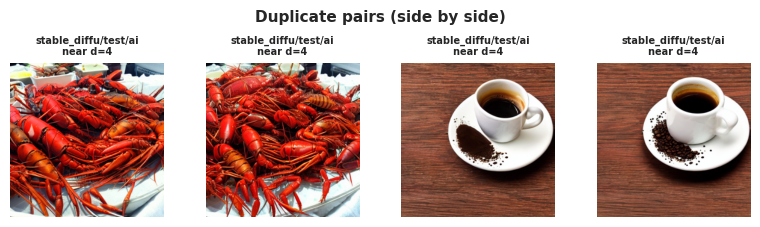

In [18]:
if EXTRACTED:
    from src.eda_utils import plot_image_grid, savefig, set_style
    set_style()
    show = pairs.sort_values("hamming", ascending=False).head(6)
    if len(show):
        rel = ok.set_index("sample_id")["raw_relpath"]
        paths, caps = [], []
        for _, r in show.iterrows():
            for side in "ab":
                paths.append(P.project_root / rel[r[f"{side}_sample_id"]])
                caps.append(f"{r[f'{side}_generator'][:12]}/{r[f'{side}_role']}/{r[f'{side}_label']}\n{r['kind']} d={r['hamming']}")
        fig = plot_image_grid(paths, caps, ncols=4, title="Duplicate pairs (side by side)")
        savefig(fig, "01_duplicate_pairs", P.figures)

In [19]:
if EXTRACTED:
    leaks = mf.leaking_test_ids(pairs) if len(pairs) else set()
    dropped = pd.concat([
        sub.loc[sub["sample_id"].isin(leaks)].assign(drop_reason="duplicate of a training image"),
        unreadable.assign(drop_reason="unreadable"),
        plan.loc[~plan["exists"]].assign(drop_reason="missing on Drive"),
    ], ignore_index=True)
    dropped.to_csv(P.manifests / "dropped_files.csv", index=False)
    log.info(f"Dropped {len(dropped)} files: {dropped['drop_reason'].value_counts().to_dict()}")
    display(dropped.groupby(["drop_reason", "generator", "role", "label"]).size().rename("n").reset_index())

2026-11-04 00:43:16 | INFO | Dropped 0 files: {}


,drop_reason,generator,role,label,n


## Step 13: save `subset_index.csv`
Notebooks 02 and 03 only read this file.

In [20]:
if EXTRACTED:
    keep = sub.loc[(sub["readable"] == True) & ~sub["sample_id"].isin(leaks)].copy()
    keep["generator_name"] = keep["generator"].map(NAMES)
    cols = ["sample_id", "raw_relpath", "generator", "generator_name", "split", "role", "label", "y",
            "filename", "ext", "imagenet_class", "class_source", "uncompressed_bytes",
            "readable", "real_format", "width", "height", "mode", "file_bytes", "jpeg_quality", "jpeg_q_exact",
            "is_gray", "md5", "phash", "inner_path", "archive_path"]
    subset_index = keep[cols].sort_values(["generator", "role", "label", "filename"]).reset_index(drop=True)
    subset_index.to_csv(P.manifests / "subset_index.csv", index=False)
    print(f"Saved {P.manifests / 'subset_index.csv'}: {len(subset_index):,} images")
    display(subset_index.groupby(["generator", "role", "label"]).size().unstack("label"))
    du = sum(f.stat().st_size for f in P.raw_subset.rglob("*") if f.is_file()) / 1e9
    print(f"raw_subset/ uses {du:.2f} GB on Drive")

Saved /content/drive/MyDrive/genimage_project/manifests/subset_index.csv: 18,000 images


label                           ai  nature
generator              role               
ADM                    test    500     500
BigGAN                 test    500     500
Midjourney             test    500     500
VQDM                   test    500     500
glide                  test    500     500
stable_diffusion_v_1_4 test    500     500
                       train  5000    5000
stable_diffusion_v_1_5 test    500     500
wukong                 test    500     500

raw_subset/ uses 4.91 GB on Drive


## Findings (fill in after running)
- Archive access: 7z version, did the split archives open in place? Listing time per generator:
- Actual inner layout vs README (top folder, split/label folders, unexpected files):
- Extraction speed (s/image, MB/s) and total extraction time:
- Benchmark (s/image with 1/4/8 workers, train vs val, copy MB/s) and the config we picked:
- Extensions / real formats of ai vs nature files:
- ImageNet class parsing (which pattern, coverage per generator):
- Filename leakage (shared nature filenames across generators / train-val):
- Duplicates found and files dropped:
- Final subset size (images, GB):
- SD1.4 / SD1.5 near-duplicates (same prompt + seed, test-test, not leakage):
- Duplicate-folder issue after deleting the runtime, and how we fixed it:

## Run before closing the tab
Uploads pending Drive writes, otherwise the next session may not see them.

In [21]:
from src.colab_setup import flush_drive
flush_drive()

[flush] Drive flushed and unmounted, safe to close the tab.
